# Data quality review: from a maize record to satellite pixels

**Felix branch · review completed 3 November 2026 (4 November UTC)**

This notebook explains what we checked, what we changed in a **separate reviewed copy**, and what still needs evidence. It is the companion to [data_guide.ipynb](data_guide.ipynb), focused on data quality rather than training.

**Main outcome:** all **11,364** original observations remain. Among the **6,117** eligible observations in our three active cohorts, the number with at least four accepted satellite months changes from **6,108 to 6,051** under our stricter screening. We quarantined uncertain Kenya dates, documented repeated locations, and tested ways to connect a point to a field. We did not discover replacement dates or confirmed new boundaries.

Read top to bottom, or jump to:

1. [What the numbers mean](#1.-What-data-are-we-talking-about?)
2. [Kenya dates](#2.-Kenya-dates:-check-the-source-before-changing-anything)
3. [Repeated coordinates](#3.-Repeated-coordinates:-same-location-does-not-prove-same-record)
4. [Plot → satellite image → pixels](#4.-How-do-we-match-a-plot-to-a-satellite-image?)
5. [Cloud screening](#5.-What-did-we-actually-do-about-clouds?)
6. [Point-to-area experiments](#6.-Can-we-turn-a-point-into-a-field-area?)
7. [Boundary matching](#7.-Can-a-predicted-boundary-identify-the-real-plot?)
8. [Inspect the separate dataset](#8.-Where-is-the-reviewed-data,-and-how-do-we-check-it?)
9. [What to improve next](#9.-What-should-we-change-next?)
10. [Reproduce the work](#10.-How-to-reproduce-the-review)

**Run All is a reading/checking workflow:** it loads the small committed aggregate summary, runs synthetic demonstrations, and optionally reads your existing local reviewed tables. It downloads nothing, writes no data, and trains no model. Stored outputs contain aggregates and illustrative figures; individual farmer records and precise field locations are not printed.


## 0. Setup and evidence

From the repository root, install the project's [requirements](../requirements.txt), then open this notebook with the `.venv` Python kernel. It uses the same packages as the original guide.

```bash
python -m pip install -r requirements.txt
```

The walkthrough works **without the 0.8 GB database or 26 GB imagery folder**. Its recorded results come from [results/quality_remediation/summary.json](../results/quality_remediation/summary.json), generated by the completed review. Reading a saved summary is different from rerunning that review. Optional local checks below verify the derived files if you have them.

The setup finds the repository whether you opened Jupyter from the root or `notebooks/`. `LOCAL_VARIANT` is the only path to change if your reviewed copy has another name.


In [1]:
from pathlib import Path
import hashlib
import importlib.util
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "results/quality_remediation/summary.json").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
SUMMARY = json.loads((ROOT / "results/quality_remediation/summary.json").read_text())
LOCAL_VARIANT = ROOT / "data/runs/quality_variant/felix-reviewed-v1"
# The environment switch is also useful to test the fresh-clone experience.
USE_LOCAL = os.environ.get("CROPYIELD_REVIEW_NO_LOCAL") != "1"
HAS_LOCAL = USE_LOCAL and (LOCAL_VARIANT / "labels_reviewed.parquet").exists()
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print("Evidence: committed aggregate review snapshot")
print("Local reviewed copy:", "available for read-only checks" if HAS_LOCAL else "absent/skipped; aggregate walkthrough still works")
print("Data downloads: none. Training: none.")


Evidence: committed aggregate review snapshot
Local reviewed copy: available for read-only checks
Data downloads: none. Training: none.


## 1. What data are we talking about?

An **observation** is a reported field-season yield, not necessarily a unique independent field location. A **field-month** is one observation paired with the selected satellite acquisition for one calendar month. Several observations can use the same satellite scene, and repeated GPS points can even use the same pixels.

Keep these three counts separate:

- **11,364 stored observations:** includes active, excluded and parked cohorts. All remain in the reviewed labels.
- **6,117 eligible observations in the active cohorts:** Kenya OAF, Malawi 2023 and primary Lacuna 2023. This is a label-selection decision.
- **6,051 with at least four months under the strict rule:** this is satellite availability, not proof of correct yield, correct field identity, or four well-spaced growth stages.

`include_primary` retains the old selection. `core_usable_under_strict_cloud_rule` is a new, separate support flag. The Lacuna folder is called `zimbabwe_lacuna_2022_2023`; the active subset counted here is its 2023 primary cohort.


In [2]:
coverage = pd.DataFrame(SUMMARY["core_coverage"])
coverage["lost_four_month_support"] = coverage["before"] - coverage["after"]
coverage["retained_share_of_previously_usable_pct"] = (100 * coverage["after"] / coverage["before"]).round(1)
display(coverage.rename(columns={"eligible": "eligible_labels", "before": "original_ge4_months", "after": "strict_ge4_months"}))
print(f"All observations retained: {SUMMARY['retained_observations']:,}")
print(f"Active eligible: {coverage.eligible.sum():,}; original support: {coverage.before.sum():,}; strict support: {coverage.after.sum():,}")
assert coverage.after.sum() == 6051
assert SUMMARY["source_observations"] == SUMMARY["retained_observations"]


,cohort,eligible_labels,original_ge4_months,strict_ge4_months,lost_four_month_support,retained_share_of_previously_usable_pct
0,kenya_oaf_2019_2020,3977,3977,3972,5,99.9
1,malawi_2023,260,251,206,45,82.1
2,zimbabwe_lacuna_2022_2023,1880,1880,1873,7,99.6


All observations retained: 11,364
Active eligible: 6,117; original support: 6,108; strict support: 6,051


### The four problems from the original data guide

| Problem | What we completed | What is still unresolved |
|---|---|---|
| Yield is measured differently across sources | Preserved provider values, units and cohort definitions; traced source metadata | Malawi's 75/100 m² interpretation; grain/cob and moisture definitions in Lacuna; provider confirmation of Kenya 2020 cut protocol |
| A point is not a field outline | Reviewed repeat locations; tested small extraction areas and same-year predicted outlines | Which real field each Kenya/Lacuna point represents, especially homestead locations |
| Clouds hide the season | Re-screened all previously accepted field-months using SCL pixels and a buffer | Thin cloud/haze, conservative false rejection, missing growth-stage coverage |
| Nearby observations look alike | Verified all 450 Kenya ≤10 m pairs stay together in frozen spatial groups/folds | Effective independent location count; spatial dependence beyond exact repeats |

**A passed integrity check is necessary, but cannot establish field identity or label accuracy.** The earlier audit passed 108 integrity checks. That proves the implemented checks, not that all scientific uncertainty has disappeared.

The preserved and derived layers are:

```text
Provider files → audit tables → frozen labels + frozen scenes + frozen splits
                                    │            │
                    source review ──┘            └── SCL pixel review
                           │                            │
                      reviewed dates             retained/null months
                           └────────────┬───────────────┘
                           separate country/cohort variant

Original DuckDB and all frozen inputs stay unchanged.
Proxy circles and predicted boundaries remain separate candidates.
```


## 2. Kenya dates: check the source before changing anything

**Question:** were the strange dates caused by our parser, or already present in the provider workbook?

We linked all **3,977** Kenya observations to their original Excel `source_row` and `unique_id`, and compared typed source dates with the audited values. They agreed. All **89** missing harvest dates were genuinely blank source cells. No missing date could be recovered by fixing the parser.

The review function [`date_proposal`](../src/cropyield/data/kenya_review.py) applies explicit Kenya season-year checks:

1. Planting year must fall between `season_year - 1` and `season_year`.
2. Harvest year must fall between `season_year` and `season_year + 1`.
3. If the remaining planting and harvest dates have `harvest <= planting`, neither can be selected as the correct one; quarantine both.

In this dataset, **5** invalid planting years and **8** ambiguous date-order pairs were found. Only the **derived** dates change: 13 planting, 8 harvest and 8 observation dates become NULL. The eight observation dates follow the quarantined harvest dates. `original_*` retains every source value.

**NULL means unknown, not repaired to the true date.** The following examples are invented to teach the rules; they are not published farmer records.


In [3]:
from cropyield.data.kenya_review import date_proposal

examples = [
    ("plausible season", "2019-03-10", "2019-08-20", 2019),
    ("planting year out of range", "2100-03-10", "2019-08-20", 2019),
    ("ambiguous reversed order", "2019-09-10", "2019-08-20", 2019),
    ("source harvest blank", "2019-03-10", None, 2019),
]
example_rows = []
for name, plant, harvest, year in examples:
    new_plant, new_harvest, decision = date_proposal(plant, harvest, year)
    example_rows.append({"synthetic_example": name, "source_plant": plant, "source_harvest": harvest,
                         "reviewed_plant": new_plant, "reviewed_harvest": new_harvest, "decision": decision})
display(pd.DataFrame(example_rows))
display(pd.Series(SUMMARY["kenya"]["date_decisions"], name="actual_Kenya_observations").to_frame())


,synthetic_example,source_plant,source_harvest,reviewed_plant,reviewed_harvest,decision
0,plausible season,2019-03-10,2019-08-20,2019-03-10,2019-08-20,retain_source_dates
1,planting year out of range,2100-03-10,2019-08-20,NaT,2019-08-20,quarantine_plant_year_outside_season_range
2,ambiguous reversed order,2019-09-10,2019-08-20,NaT,NaT,quarantine_both_ambiguous_date_order
3,source harvest blank,2019-03-10,NaN,2019-03-10,NaT,retain_source_dates


,actual_Kenya_observations
retain_source_dates,3964
quarantine_both_ambiguous_date_order,8
quarantine_plant_year_outside_season_range,5


**What this fixes:** downstream users can avoid treating impossible dates as reliable phenology information. **What it does not fix:** the true dates remain unknown, other cohorts' dates have not been reviewed in this Kenya-specific step, and late harvests remain flagged.

The existing satellite windows are fixed by cohort/year, not by each record's harvest date: Kenya February–September of the season year; Malawi and active Lacuna October of the previous year–June of the harvest year. Therefore, this date quarantine **does not shift any satellite window or choose another image**. A future forecast task needs an explicit prediction date and imagery available by that date. A whole-season estimate and a pre-harvest forecast are different tasks.

**To improve:** request corrected dates linked to the same provider IDs and clarify late harvests. A future version can apply confirmed corrections with provenance. Guessing a replacement year would conceal uncertainty.


## 3. Repeated coordinates: same location does not prove same record

The review compared source IDs, full source rows, yields, monthly bands and frozen split assignments.

- **203 observations in 95 exact-coordinate groups** form **133 pairs**. All pairs have distinct source IDs and different yields, but identical complete monthly satellite series.
- No pair is an identical full source record, including after ignoring the source ID.
- Within 10 m there are **560 observations**, **253 connected groups** and **450 pairs**. Every pair already shares its frozen spatial group and fold.
- None of the exact pairs crosses years. Of the near pairs, 46 cross years.

A group with several observations contributes several pairs, so pair count and row count are different. A connected ≤10 m group can also form a chain; not every member must be within 10 m of every other member.

**Our action:** retain the yields and coordinates; add `exact_coordinate_group_id` and `coordinate_review_group_id`. We neither deleted observations nor moved points to neighbouring fields.

**Why:** identical imagery with different measured yields may represent location rounding, a homestead used for multiple fields, separate crop cuts, or another recording issue. The available evidence does not distinguish these explanations. These rows should not be treated as independent satellite locations.


In [4]:
kenya = SUMMARY["kenya"]
repeat_metrics = {name: kenya[name] for name in [
    "exact_coordinate_observations", "exact_coordinate_groups", "exact_pairs",
    "exact_pairs_same_monthly_bands", "exact_pairs_same_yield",
    "near_10m_observations", "near_10m_groups", "near_10m_pairs",
    "near_pairs_grouped_in_frozen_spatial_split",
]}
display(pd.Series(repeat_metrics, name="recorded_result").to_frame())
assert kenya["exact_pairs_same_monthly_bands"] == kenya["exact_pairs"]
assert kenya["near_pairs_grouped_in_frozen_spatial_split"]


,recorded_result
exact_coordinate_observations,203
exact_coordinate_groups,95
exact_pairs,133
exact_pairs_same_monthly_bands,133
exact_pairs_same_yield,0
near_10m_observations,560
near_10m_groups,253
near_10m_pairs,450
near_pairs_grouped_in_frozen_spatial_split,True


**To improve:** ask the provider whether the repeated location is a farm/homestead or sampled field, and request field-level identifiers or outlines. Until then, report both observations and unique location groups; keep each group together in any evaluation. A separately declared group-weighted or group-aggregated sensitivity analysis may assess dependence later, but averaging yields is not a confirmed correction and has not been applied here.

### A critical Kenya source clarification

The workbook permits homestead/nearby GPS (`Variables!C40:C41`). Its Kenya acreage may cover all land of the same crop and field type rather than the one sampled field (`Description!B2`, `Variables!C75:C76`). It is estimated, not a surveyed outline area.

Consequently, **drawing a circle whose area equals Kenya `field_area_ha` would create an unsupported field boundary**. We keep the source area value and add a scope caveat. A larger buffer does not repair an incorrect location.


## 4. How do we match a plot to a satellite image?

There are two separate questions:

1. **Geometric lookup:** given a coordinate or polygon, which image pixels cover it?
2. **Field identity:** does that location/outline actually belong to the field whose maize was measured?

Our code can perform the first precisely. Malawi's surveyed outlines give stronger evidence for the second. A Kenya/Lacuna point, a circle, or a predicted boundary alone cannot prove field identity.

### The actual pipeline, step by step

| Step | What happens | Where to read the code |
|---|---|---|
| Link the label | Preserve `obs_id`, source ID, source row, country, season and location | [labels.py](../src/cropyield/data/labels.py) |
| Define the time window | Use the fixed cohort/year window | [cohorts.py](../src/cropyield/data/cohorts.py) |
| Find candidate scenes | Search by place/time; order monthly candidates by tile cloud cover, date and ID; try up to three | `month_candidates` in [step5_download_imagery.py](../scripts/step5_download_imagery.py) |
| Put geometry on the image grid | Transform longitude/latitude into local UTM metres; construct a snapped 64 × 64 grid at 10 m | `grid_for` in the same script |
| Select field pixels | Transform the field geometry into that grid; make touched-pixel and pixel-centre masks | `aoi_for`, then [read_chip](../src/cropyield/satellite/chips.py) |
| Read and quality-check pixels | Read reflectance and SCL; use the appropriate mask and retain acquisition identity | `read_asset`, `download_scene` |
| Reduce to one monthly row | Take the median of valid field pixels for each band; point observations have one pixel | [monthly_series](../src/cropyield/satellite/monthly.py) |
| Join to yield | `obs_id` links the monthly row to the label; `(obs_id, month)` identifies a monthly row | [schema.sql](../sql/schema.sql) |

A **scene** is a satellite acquisition covering a large region. A **chip** is our 640 m × 640 m local image window. A **field mask** selects the pixels used for that label. **The entire 640 m chip is not the field.**

The completed cloud review reuses the **frozen scene IDs and acquisition dates**; it does not repeat the scene-selection step or search for replacement images.


### 4a. A point becomes a row and column on a grid

Longitude/latitude are angles. UTM gives local x/y coordinates in metres. The raster's affine transform describes where its upper-left corner is and how far each pixel spans. `rowcol` converts x/y to pixel indexes.

The next cell calls the repository's actual `grid_for` and `aoi_for` functions using an **invented point**. Loading the script only defines its functions; its download entry point is not called. Notice that the returned mask selects **one** pixel, even though the chip holds 4,096 pixels.


In [5]:
from rasterio.transform import rowcol, xy
from rasterio.warp import transform as transform_coordinates

spec = importlib.util.spec_from_file_location("review_downloader", ROOT / "scripts/step5_download_imagery.py")
downloader = importlib.util.module_from_spec(spec)
spec.loader.exec_module(downloader)
example_point = {"longitude": 35.0, "latitude": 0.1,
                 "geometry": {"type": "Point", "coordinates": [35.0, 0.1]}}
grid = downloader.grid_for(example_point, size=64, resolution=10)
point_mask, fully_inside_chip = downloader.aoi_for(example_point, grid)
x, y = transform_coordinates("EPSG:4326", grid["crs"], [35.0], [0.1])
r, c = rowcol(grid["transform"], x[0], y[0])
centre_x, centre_y = xy(grid["transform"], r, c)
assert point_mask[r, c] and point_mask.sum() == 1 and fully_inside_chip
print(f"Synthetic example CRS: {grid['crs']}; pixel (row, column): ({r}, {c})")
print(f"Chip: {grid['width']} × {grid['height']} pixels; selected field pixels: {point_mask.sum()}")
print(f"Point-to-selected-pixel-centre distance: {np.hypot(x[0]-centre_x, y[0]-centre_y):.2f} m")


Synthetic example CRS: EPSG:32636; pixel (row, column): (31, 32)
Chip: 64 × 64 pixels; selected field pixels: 1
Point-to-selected-pixel-centre distance: 4.79 m


### 4b. A polygon selects several pixels; a proxy is a different assumption

For a polygon, the original monthly median uses pixels whose **centres lie inside** the field. If no pixel centre lies inside a very thin/small polygon, it falls back to all touched pixels. The strict cloud check instead inspects **every touched pixel**, including edge pixels.

The synthetic diagram below uses a 10 m grid and the same rasterization options as the production code. The black outline is a made-up field, not a recovered Kenya plot. Its point and proposed 20 m-radius support are also illustrative. Even an interior pixel covers a finite area and can cross an edge; a mask cannot eliminate subpixel mixing.


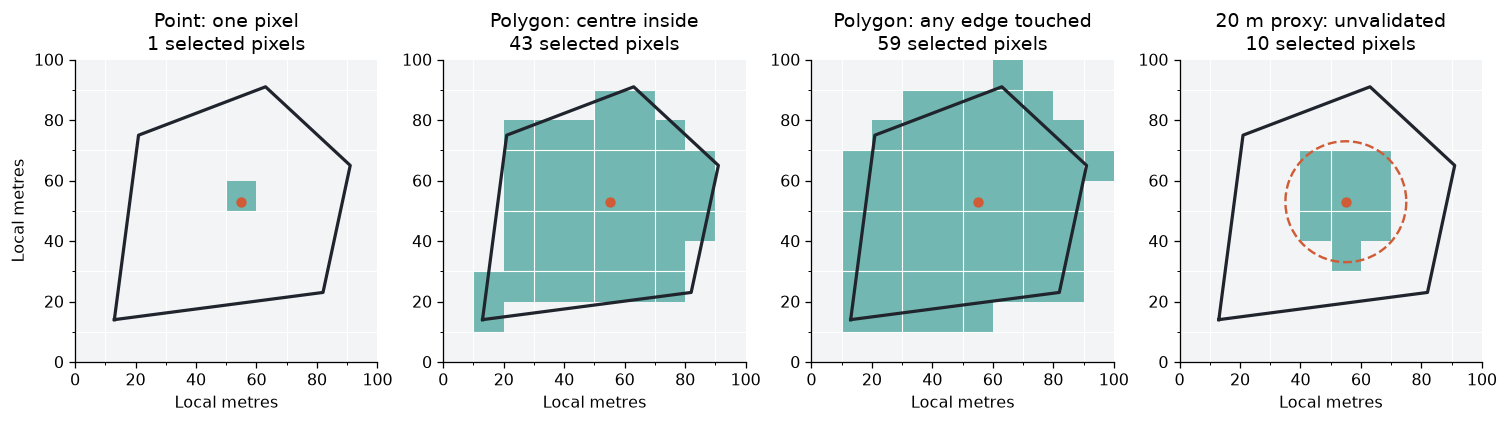

In [6]:
from shapely.geometry import Polygon, Point, mapping
from rasterio.features import rasterize
from rasterio.transform import from_origin
from matplotlib.colors import ListedColormap

# Small metric-coordinate demonstration, independent of any real farmer location.
field = Polygon([(13, 14), (82, 23), (91, 65), (63, 91), (21, 75)])
point = Point(55, 53)
support = point.buffer(20)
demo_transform = from_origin(0, 100, 10, 10)
def raster_mask(geometry, touched):
    return rasterize([(mapping(geometry), 1)], out_shape=(10, 10),
                     transform=demo_transform, all_touched=touched, dtype="uint8").astype(bool)

interior = raster_mask(field, False)
touched = raster_mask(field, True)
point_pixel = raster_mask(point, True)
proxy_pixels = raster_mask(support, False)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.7), layout="constrained")
for ax, mask, title in zip(axes, [point_pixel, interior, touched, proxy_pixels],
                         ["Point: one pixel", "Polygon: centre inside", "Polygon: any edge touched", "20 m proxy: unvalidated"]):
    ax.imshow(mask, extent=(0, 100, 0, 100), origin="upper", vmin=0, vmax=1,
              cmap=ListedColormap(["#f3f4f6", "#72b7b2"]))
    ax.plot(*field.exterior.xy, color="#20242c", linewidth=2)
    ax.scatter(point.x, point.y, color="#cf5c36", s=30, zorder=5)
    if ax is axes[3]:
        ax.plot(*support.exterior.xy, color="#cf5c36", linestyle="--")
    ax.set(title=f"{title}\n{mask.sum()} selected pixels", xlabel="Local metres", xlim=(0, 100), ylim=(0, 100))
    ax.set_xticks(np.arange(0, 101, 10), minor=True)
    ax.set_yticks(np.arange(0, 101, 10), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.7)
axes[0].set_ylabel("Local metres")
plt.show()


### 4c. From selected pixels to one monthly number

For each band, the original table takes the **median of valid field pixels**. This is spatial aggregation within the selected acquisition, **not a monthly median across many acquisition dates**. A point's single-pixel result has no within-field averaging.

Reflectance is a unitless light measurement; the downloader applies the scene metadata's scale and offset once. Reflectance bands are read onto the common 10 m grid using bilinear resampling. Native 20 m bands do not gain 10 m detail. SCL contains category numbers and therefore uses nearest-neighbour resampling. Resampling may alter the signal; it is not guaranteed unbiased.

In the synthetic example below, one bad pixel is excluded before taking the median. This explains the **original extraction**. Our later strict review cannot recalculate pixel medians from a stored median alone; it keeps or withholds the whole monthly row.


In [7]:
synthetic_red = np.array([0.12, 0.13, 0.14, 0.90])
synthetic_nir = np.array([0.40, 0.42, 0.44, 0.95])
valid_pixels = np.array([True, True, True, False])
red_median = np.median(synthetic_red[valid_pixels])
nir_median = np.median(synthetic_nir[valid_pixels])
ndvi_from_band_medians = (nir_median - red_median) / (nir_median + red_median)
print(f"Synthetic band medians: red={red_median:.3f}, NIR={nir_median:.3f}")
print(f"NDVI from those band medians: {ndvi_from_band_medians:.3f}")
print("A stored monthly median cannot tell us what a different subset of pixels would yield.")


Synthetic band medians: red=0.130, NIR=0.420
NDVI from those band medians: 0.527
A stored monthly median cannot tell us what a different subset of pixels would yield.


## 5. What did we actually do about clouds?

**Completed:** inspected SCL classification pixels for **all 1,307 unique frozen scenes and all 84,967 previously accepted field-months**, including parked/excluded cohorts. There were no failed scene reads. We downloaded scene metadata and small SCL windows, not the full reflectance archive. We did not inspect every historical Sentinel-2 acquisition or visually certify every image.

**SCL** is the Sentinel-2 Scene Classification Layer. It estimates whether pixels represent vegetation, bare land, water, cloud, shadow, etc. [Copernicus documents it here](https://sentiwiki.copernicus.eu/web/s2-processing). It is useful evidence, but can miss thin cloud or haze.

| Rule | Original accepted imagery | Separate strict review |
|---|---|---|
| Allowed SCL classes | 4 vegetation, 5 bare land, 6 water | 4 vegetation, 5 bare land |
| AOI condition | At least 80% touched pixels clear and all bands finite | Every touched pixel must pass the new SCL rule; original finite band values are retained |
| Extra cloud margin | No explicit buffer | 60 m around cloud/shadow classes 3, 8, 9, 10 |
| Uncertain classification | Governed by original clear-mask test | Nodata/unknown near the AOI makes it unverified; withheld |
| Failed field-month | Original download may try another candidate | Entire stored monthly band row becomes NULL; no replacement scene searched |

The **60 m** choice is conservative and has not been established as optimal. This policy also excludes water/other land classes, so its losses are not all confirmed clouds. The review reconstructs the original grid, checks frozen field-pixel counts, uses a context halo, and nearest-neighbour samples native **20 m SCL**. It does not create new 10 m classification information.


In [8]:
cloud = SUMMARY["cloud_totals"]
cloud_counts = pd.Series({
    "unique scenes": cloud["unique_scenes"],
    "accepted field-months reviewed": cloud["reviewed_field_months"],
    "field-months retained": cloud["kept_field_months"],
    "field-months withheld": cloud["reviewed_field_months"] - cloud["kept_field_months"],
    "unverified context (subset of withheld)": cloud["unverified_field_months"],
    "field-months not reviewed": cloud["unreviewed_field_months"],
}, name="count")
display(cloud_counts.to_frame())
assert cloud["reviewed_field_months"] - cloud["kept_field_months"] == 2586
assert cloud["unreviewed_field_months"] == 0


,count
unique scenes,1307
accepted field-months reviewed,84967
field-months retained,82381
field-months withheld,2586
unverified context (subset of withheld),1288
field-months not reviewed,0


### Why a cloud outside the plot can still reject the month

This synthetic SCL example calls the actual [`cloud_masks`](../src/cropyield/satellite/cloud_review.py) function. The single orange point is not directly cloudy, but is within 60 m of a cloud edge. The buffer rejects it. Native SCL resolution is 20 m; these are illustrative category cells on a 10 m grid, not newly observed 10 m SCL.


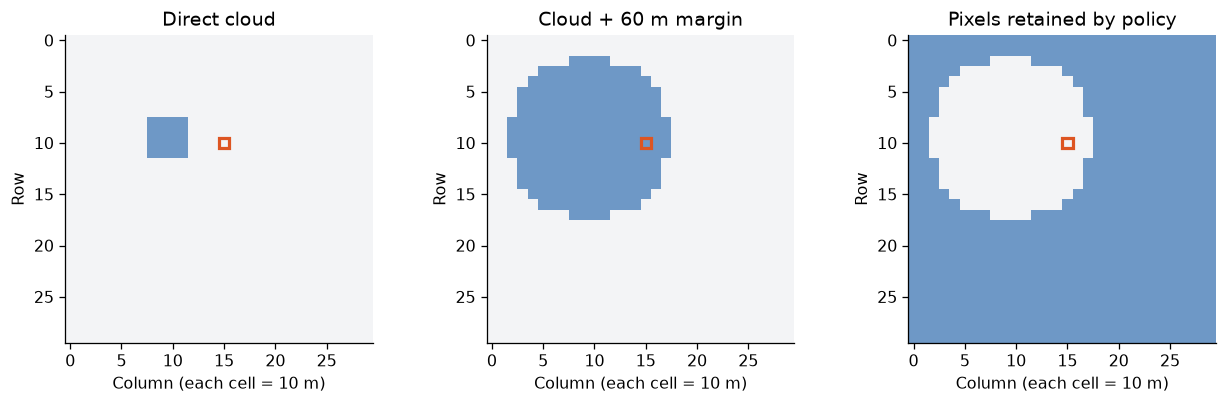

Orange point: no direct cloud, but rejected because the cloud buffer reaches it.


In [9]:
from cropyield.satellite.cloud_review import cloud_masks
from matplotlib.patches import Rectangle

scl_demo = np.full((30, 30), 4, dtype=np.uint8)  # synthetic vegetation
scl_demo[8:12, 8:12] = 9                       # synthetic high-probability cloud
keep_demo, cloud_buffer_demo, unknown_demo = cloud_masks(scl_demo, buffer_m=60, resolution=10)
point_r, point_c = 10, 15
assert scl_demo[point_r, point_c] == 4 and not keep_demo[point_r, point_c]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), layout="constrained")
for ax, mask, title in zip(axes, [scl_demo == 9, cloud_buffer_demo, keep_demo],
                         ["Direct cloud", "Cloud + 60 m margin", "Pixels retained by policy"]):
    ax.imshow(mask, cmap=ListedColormap(["#f3f4f6", "#6e98c6"]), vmin=0, vmax=1)
    ax.add_patch(Rectangle((point_c-0.5, point_r-0.5), 1, 1, fill=False, edgecolor="#dd5522", linewidth=2))
    ax.set(title=title, xlabel="Column (each cell = 10 m)", ylabel="Row")
plt.show()
print("Orange point: no direct cloud, but rejected because the cloud buffer reaches it.")


### What the stricter rule costs

**82,381** field-months remain and **2,586** are withheld. Among the withheld months, **1,288** have uncertain SCL context. Direct cloud/shadow touches 82 AOIs; buffered cloud/shadow touches 1,703. Those categories overlap and must not be added together.

At least four months is only our existing coverage threshold. Four adjacent months can still miss planting or peak growth. The graph separates retained support from lost support among observations that previously had four months. Malawi loses **45 of 251** such observations (about 18%), so a strict mask can reduce the available sample substantially and unevenly.


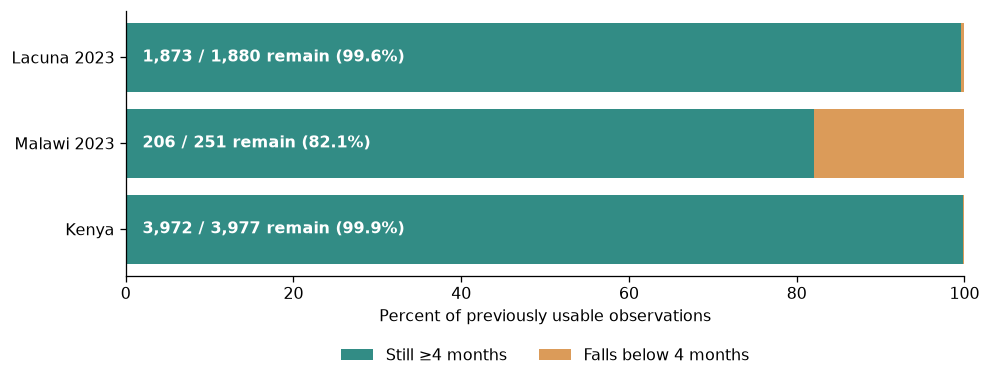

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 3.2), layout="constrained")
names = ["Kenya", "Malawi 2023", "Lacuna 2023"]
share = 100 * coverage["after"] / coverage["before"]
ax.barh(names, share, color="#328c85", label="Still ≥4 months")
ax.barh(names, 100-share, left=share, color="#db9b59", label="Falls below 4 months")
for i, row in coverage.iterrows():
    ax.text(2, i, f"{row['after']:,} / {row['before']:,} remain ({share.iloc[i]:.1f}%)",
            va="center", color="white", weight="bold")
ax.set(xlim=(0, 100), xlabel="Percent of previously usable observations")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
plt.show()


**What changed in the derived tables:** rejected or unverified monthly bands become NULL, never zero; retained numeric reflectance is unchanged; seasonal indices are recomputed from remaining months. Already missing months remain missing. This is a whole-month rejection approach because the database contains aggregates, not all original pixels.

**What was not updated:** Presto/MOSAIKS embeddings still describe the original imagery selection and are omitted from the assembled variant. They must be regenerated from the chosen reviewed inputs before they can be called features of that variant. AlphaEarth also has its own source/compositing and temporal support; masking our Sentinel-2 months does not clean an externally supplied embedding.

**To improve:** inspect a stratified sample of retained, rejected and uncertain scenes; compare an independent score such as [Cloud Score+](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_CLOUD_SCORE_PLUS_V1_S2_HARMONIZED); test declared buffer sizes against image-quality evidence; and search additional acquisitions to recover Malawi coverage. Cloud Score+ uses identifiers tied to its source L1C assets, so pairing with Earth Search L2A scenes needs verified tile/acquisition matching, not an assumption of identical IDs. None of these follow-ups has been run here.


## 6. Can we turn a point into a field area?

We tested **extraction supports**: circles with radii **10, 20 and 30 m** around each eligible Kenya/Lacuna point. These are candidate areas from which one could extract satellite values. They are **not inferred field boundaries**. The original monthly features still use their original supports.

There are 11,931 Kenya candidates (3,977 × 3) and 5,640 Lacuna candidates (1,880 × 3). No Kenya acreage was used and no point was moved.

### Test the geometric idea where we know an outline

For all **260 Malawi 2023 surveyed polygons**, we used each polygon's stored representative point and shifted it by synthetic distances of 0, 10, 20 or 30 m. Nonzero offsets use four directions. We average directions within each field first, then summarize across fields, so every field gets equal weight.

Two quantities answer different questions:

- **Support inside field** = overlap area / support area. How much of our extraction area belongs to the known field?
- **Field covered** = overlap area / field area. How much of the field are we sampling?

A tiny support may be entirely inside the field yet cover very little of it. A larger support may sample more field and more neighbouring land. Neither quantity directly measures maize purity or spectral accuracy.


,radius_m,synthetic_offset_m,fields,support_inside_field_pct,field_covered_pct
4,20,0,260,100.0,21.0
7,20,30,260,71.6,15.4
8,30,0,260,98.8,44.6
11,30,30,260,64.1,31.0


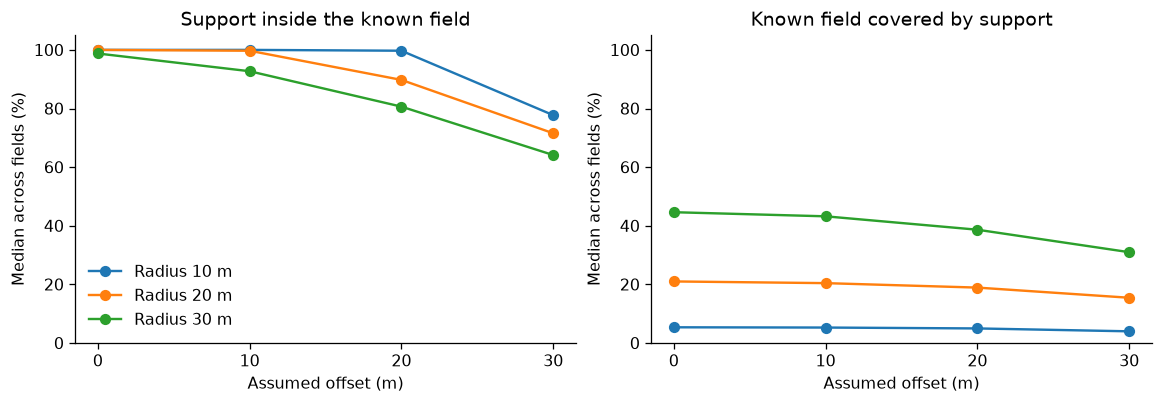

In [11]:
proxy_results = pd.DataFrame(SUMMARY["point_area_validation"])
selected = proxy_results.query("radius_m in [20, 30] and synthetic_offset_m in [0, 30]").copy()
selected["support_inside_field_pct"] = 100 * selected["median_fraction_support_inside_field"]
selected["field_covered_pct"] = 100 * selected["median_fraction_field_covered"]
display(selected[["radius_m", "synthetic_offset_m", "fields", "support_inside_field_pct", "field_covered_pct"]].round(1))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
for radius, part in proxy_results.groupby("radius_m"):
    axes[0].plot(part.synthetic_offset_m, 100*part.median_fraction_support_inside_field, "o-", label=f"Radius {radius} m")
    axes[1].plot(part.synthetic_offset_m, 100*part.median_fraction_field_covered, "o-", label=f"Radius {radius} m")
for ax, title in zip(axes, ["Support inside the known field", "Known field covered by support"]):
    ax.set(title=title, xlabel="Assumed offset (m)", ylabel="Median across fields (%)", ylim=(0, 105), xticks=[0, 10, 20, 30])
axes[0].legend(frameon=False)
plt.show()


A 20 m support has about 100% median overlap purity with zero offset, yet covers only **21%** of a field. With a 30 m offset, purity falls to **72%**. With a 30 m radius and 30 m offset, it is **64%**.

These offsets are **sensitivity assumptions, not measured GPS errors**. The Malawi representative points were derived from the polygons themselves, so zero-offset results are optimistic compared with Kenya homestead coordinates. We cannot transfer those percentages directly to Kenya as an accuracy estimate.

The next recorded figure illustrates one Malawi outline in relative metres. It is an example, not the 260-field median above.


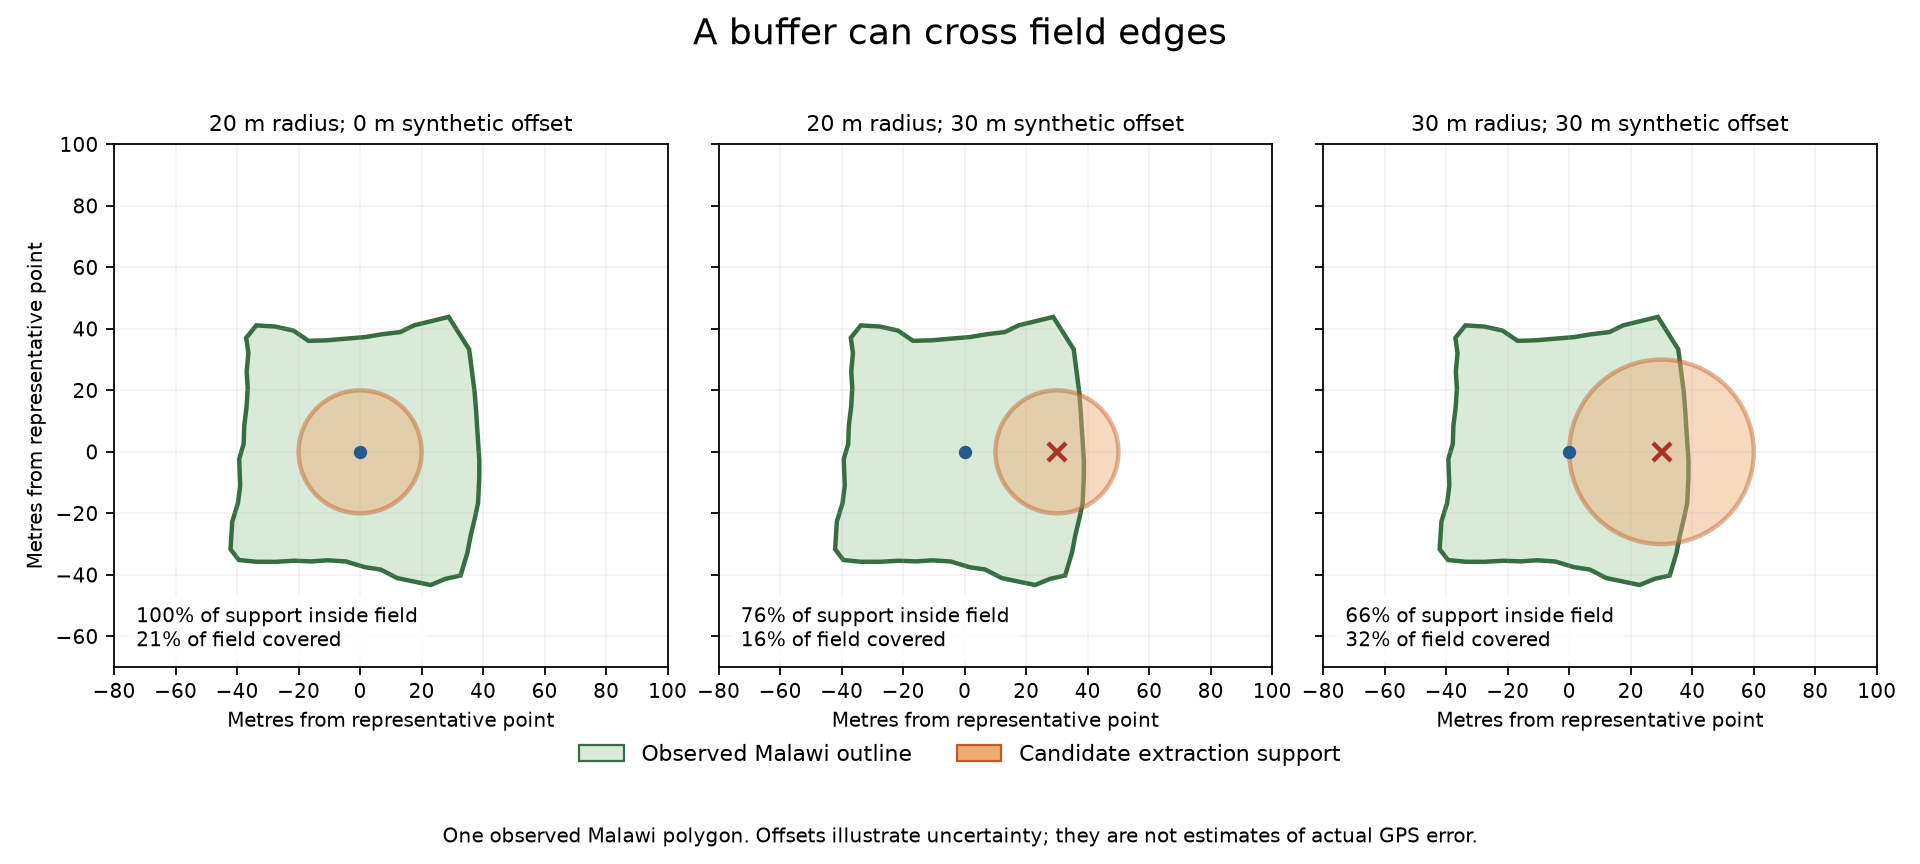

In [12]:
display(Image(filename=str(ROOT / "results/quality_remediation/point_area_example.png")))


**How to improve the experiment:** obtain independent GPS accuracy or provider-linked boundaries; compare original point, small support, and surveyed outline using the same acquisitions; record pixel counts and edge contamination; test whether the geometry behaves consistently across countries and field sizes. Choose supports using location/imagery evidence, not the yield that a later model should predict. Do not silently make a circle the new field.


## 7. Can a predicted boundary identify the real plot?

We tried [Fields of the World, Global second edition](https://source.coop/ftw/global-data-2e): annual predicted boundaries for 2017–2025, from Fields of the World/Taylor Geospatial, licensed CC BY 4.0. These are model outputs rather than surveyed field truth.

The completed search used all **203 Kenya records with repeated exact coordinates** and **260 Malawi polygons**. It did **not** search all 3,977 Kenya records or Lacuna.

### What the matching code does

1. Pick the same year as the label and the relevant UTM zone's public GeoParquet file.
2. Read relevant byte ranges and filter locally; retain source polygon ID, year and score.
3. Work in a common metric coordinate system. For Kenya, measure candidate distance to the point. For Malawi, measure distance to the surveyed polygon. Keep candidates within **30 m**; record point containment separately.
4. Distinguish no candidate, one candidate requiring review, and multiple ambiguous candidates. A time limit or read failure is not a no-candidate result.
5. For Malawi only, compare with the surveyed outline using intersection-over-union: `area(overlap) / area(union)`. Best IoU is an optimistic overlap diagnostic, not proof of the selected field's identity.
6. Save candidates separately. Never choose a polygon using the yield, move the point, or replace surveyed geometry.

See [`boundary_candidates.py`](../src/cropyield/data/boundary_candidates.py). The current nearest-distance/ID ordering is deterministic; it is not a validated field-matching classifier.


In [13]:
match_coverage = pd.DataFrame(SUMMARY["boundary_match_coverage"])
match_coverage["candidate_share_pct"] = (100 * match_coverage.with_candidate / match_coverage.observations).round(2)
display(match_coverage)
display(pd.Series(SUMMARY["boundary_review"]["status_counts"], name="observations").to_frame())
assert match_coverage.observations.sum() == 463


,country,observations,with_candidate,candidate_share_pct
0,KEN,203,0,0.00
1,MWI,260,4,1.54


,observations
no_candidate_unknown,459
ambiguous_multiple_candidates,2
one_predicted_candidate_requires_review,2


**Result:** Kenya had **0/203** records with a candidate in range. Malawi had **4/260**, with best IoU values **0.141, 0, 0.557 and 0.067**. Two records had multiple candidates; two had a single candidate still requiring review. Regional product coverage and coordinate/geometry handling were checked, so this was not explained by a simple coordinate-order or query error.

There are **no confirmed replacements**. A missing prediction does not mean a field is absent or its GPS is wrong. The source omits polygons below 900 m², has early-year imagery gaps, and reports limitations for smallholder fields. Its scores are uncalibrated. Annual image inputs can extend beyond harvest and do not establish forecast-time availability.

**A defensible future matching rule:** start with provider-linked field ID/outlines; otherwise retain all plausible same-year candidates, check independent GPS accuracy and visible edges, and validate a declared rule against surveyed polygons. Keep uncertain cases unresolved. Satellite texture or a segmentation model can suggest edges, but cannot determine which farmer's yield belongs to which nearby field without linkage evidence.


## 8. Where is the reviewed data, and how do we check it?

The local assembled copy is `data/runs/quality_variant/felix-reviewed-v1/`. It is organized by country and cohort. **Detailed derivatives, masks and candidate geometry stay in ignored `data/runs/`; they are not uploaded by pushing this notebook.** A fresh clone contains the walkthrough, code and aggregate evidence. The commands below recreate local derivatives when the team database is available.

```text
data/runs/quality_variant/felix-reviewed-v1/
├── report.html
├── summary.json
├── labels_reviewed.parquet                 # all 11,364 observations
├── KEN/kenya_oaf_2019_2020/
├── MWI/malawi_2023/
├── MWI/malawi_2022/                        # retained but not an active cohort
├── ZWE/zimbabwe_lacuna_2022_2023/
└── ZWE/zimbabwe_2024/                      # parked cohort retained

Each cohort: labels_reviewed.parquet, cleaned_monthly_bands.parquet,
             clean_season_indices.parquet, field_coverage.parquet
Kenya also:  date_review.csv, coordinate_pairs.csv
Selected cohorts also: boundary_candidate_review.csv and candidate files
```

| Column/file | Meaning |
|---|---|
| `original_plant_date`, `original_harvest_date`, `original_obs_date` | Frozen source dates preserved |
| `plant_date`, `harvest_date`, `obs_date` | Reviewed Kenya dates; other cohorts unchanged |
| `date_review_decision` | Why a Kenya date was retained/quarantined; other cohorts explicitly not reviewed here |
| `original_impossible_date`, `original_date_outside_window` | Original flags, not assertions about revised dates |
| `exact_coordinate_group_id`, `coordinate_review_group_id` | Dependence/review groups; not new field identities |
| `include_primary` | Original label eligibility, unchanged |
| `retained_months`, `retains_four_months` | Coverage under the strict policy |
| `core_usable_under_strict_cloud_rule` | Active cohort + original eligibility + ≥4 strict months |
| `kept_by_cloud_policy` in monthly bands | Whether an originally available monthly row passes the new review |

### Optional local checks

The next cells read local tables if available. They compare hashes, original measurements, all date changes, and retained/withheld band values. They open DuckDB **read-only** if present. They print only aggregate results and do not rewrite any data. Missing local files cause an explicit skip, not a claim that checks passed.


In [14]:
def file_sha256(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

if HAS_LOCAL:
    local_manifest = json.loads((LOCAL_VARIANT / "summary.json").read_text())
    frozen_path = ROOT / "data/processed/labels_v1.parquet"
    assert file_sha256(frozen_path) == local_manifest["original_labels_sha256"]
    for name, expected in local_manifest["output_sha256"].items():
        assert file_sha256(LOCAL_VARIANT / name) == expected, f"Derived file differs: {name}"
    original = pd.read_parquet(frozen_path).set_index("obs_id").sort_index()
    reviewed = pd.read_parquet(LOCAL_VARIANT / "labels_reviewed.parquet").set_index("obs_id").sort_index()
    assert original.index.is_unique and reviewed.index.is_unique
    pd.testing.assert_index_equal(original.index, reviewed.index)
    protected_columns = ["yield_kg_ha", "lat", "lon", "geometry_wkt", "field_area_ha",
                         "include_primary", "exclusion_reason", "cluster_2km", "season_start", "season_end"]
    pd.testing.assert_frame_equal(original[protected_columns], reviewed[protected_columns])
    date_changes = {}
    for column in ["plant_date", "harvest_date", "obs_date"]:
        source = pd.to_datetime(original[column])
        preserved = pd.to_datetime(reviewed[f"original_{column}"])
        derived = pd.to_datetime(reviewed[column])
        pd.testing.assert_series_equal(source, preserved, check_names=False)
        changed = ~(source.eq(derived) | (source.isna() & derived.isna()))
        assert derived.loc[changed].isna().all()
        assert reviewed.loc[changed, "cohort"].eq("kenya_oaf_2019_2020").all()
        date_changes[column] = int(changed.sum())
    assert date_changes == {"plant_date": 13, "harvest_date": 8, "obs_date": 8}
    assert reviewed.core_usable_under_strict_cloud_rule.sum() == coverage.after.sum()
    print(f"PASS: {len(reviewed):,} rows; measurements, coordinates, eligibility, groups and windows unchanged.")
    print("PASS: derived output hashes; original dates preserved; date-to-NULL counts:", date_changes)
else:
    print("SKIPPED local integrity checks: reviewed copy is absent or disabled.")


PASS: 11,364 rows; measurements, coordinates, eligibility, groups and windows unchanged.
PASS: derived output hashes; original dates preserved; date-to-NULL counts: {'plant_date': 13, 'harvest_date': 8, 'obs_date': 8}


In [15]:
if HAS_LOCAL:
    band_columns = ["b02", "b03", "b04", "b05", "b06", "b07", "b08", "b8a", "b11", "b12"]
    monthly_paths = sorted(LOCAL_VARIANT.glob("*/*/cleaned_monthly_bands.parquet"))
    strict_monthly = pd.concat([pd.read_parquet(p) for p in monthly_paths], ignore_index=True)
    assert not strict_monthly.duplicated(["obs_id", "month"]).any()
    assert strict_monthly.loc[~strict_monthly.kept_by_cloud_policy, band_columns].isna().all().all()
    assert np.isfinite(strict_monthly.loc[strict_monthly.kept_by_cloud_policy, band_columns]).all().all()
    print("PASS: withheld/missing bands are NULL; retained bands are finite; monthly keys are unique.")
    db_path = ROOT / "data/cropyield.duckdb"
    if db_path.exists():
        import duckdb
        team_db = json.loads((ROOT / "configs/team_database_v1.json").read_text())
        assert db_path.stat().st_size == team_db["bytes"] and file_sha256(db_path) == team_db["sha256"]
        with duckdb.connect(str(db_path), read_only=True) as con:
            original_monthly = con.execute("SELECT obs_id, month, " + ", ".join(band_columns) + " FROM monthly_bands").df()
        before = original_monthly.set_index(["obs_id", "month"]).sort_index()
        after = strict_monthly.set_index(["obs_id", "month"]).sort_index()
        pd.testing.assert_index_equal(before.index, after.index)
        keep_keys = after.index[after.kept_by_cloud_policy]
        np.testing.assert_array_equal(before.loc[keep_keys, band_columns].to_numpy(), after.loc[keep_keys, band_columns].to_numpy())
        print("PASS: team database fingerprint and every retained band value exactly match originals.")
    else:
        print("SKIPPED comparison with original monthly bands: team database absent.")
else:
    print("SKIPPED local monthly-band checks: reviewed copy is absent or disabled.")


PASS: withheld/missing bands are NULL; retained bands are finite; monthly keys are unique.


PASS: team database fingerprint and every retained band value exactly match originals.


**Recorded validation at the end of the review:** all 27 protected inputs were byte-identical; 250 data-pipeline tests passed and two Windows-only tests were skipped. After final assembler edits, its 16 tests passed again. This notebook's small examples and assertions explain/check selected claims; they do not rerun the remote all-scene review or replace that test suite.

The cloud run records source commit `2d8f2e3`, input hashes, code hashes, mask hashes and output hashes. Later formatting-only changes have a separate provenance note. Reusing the exact recorded code matters for a byte-for-byte reproduction; running today's code in a new directory is a new run and should keep its own manifest.


## 9. What should we change next?

These are proposed next steps, **not completed improvements or demonstrated prediction gains**. A stricter filter alone does not establish better data or better predictions. Keep a declared reference version and compare proposed versions on scientific evidence.

| Priority / problem | Next concrete action | How we would know it helped |
|---|---|---|
| 1 · Field identity | Ask OAF for sampled-field IDs/outlines, GPS accuracy and the meaning of repeated/homestead points; seek linked Lacuna outlines | More observations with independently confirmed field identity; fewer unresolved shared locations |
| 1 · Yield definition | Resolve Malawi 75/100 m² cut interpretation; confirm Lacuna harvested product/moisture and Kenya 2020 protocol | Provider-confirmed definitions and traceable conversion rules; no assumption-based rescaling |
| 1 · Date uncertainty | Request corrections for flagged source IDs; document crop calendars and late harvests | Confirmed replacement dates and a justified season/prediction cutoff |
| 2 · Cloud quality | Blind-review a stratified sample of retained/rejected/unknown scenes, preferably by two reviewers; compare independent cloud scores and declared 0/20/40/60 m buffers | Estimate residual cloud and false-rejection rates by cohort; select a justified tradeoff before using test outcomes |
| 2 · Coverage loss | Search more acquisitions; make quality-controlled per-pixel composites where appropriate; retain original acquisition dates and counts | Recover genuinely clear growth-stage observations, especially Malawi, without adding cloudy values |
| 2 · Spatial support | Compare point/small-support/surveyed-outline extraction on the same scenes, including realistic GPS offsets and edge effects | Independently validated matching/overlap performance; stable image summaries, not simply more pixels |
| 3 · Dependence | Keep repeated/nearby locations grouped; report independent groups and shared-pixel counts | No cross-fold leakage; transparent effective sample size |
| 3 · Feature consistency | Rebuild features from the selected reviewed imagery and document each representation's temporal support | Every feature is traceable to the chosen masks, scenes, supports and dates |

**Before calling a reviewed version ready:** resolve or explicitly document the important label/location limitations; record the cloud rule and missingness by country/season; verify hashes and joins; retain fixed spatial groups; freeze a named version. If a question cannot be resolved, preserve uncertainty and define a transparent sensitivity analysis rather than silently relabeling it.

For a future geospatial foundation model, these checks still apply. Presto needs consistent time-series inputs and missing-value handling. Annual embeddings such as AlphaEarth require a clearly declared year/time support and separate provenance. Neither can recover a missing measurement protocol or establish field identity simply by being a larger model. This notebook does not fine-tune any model.


## 10. How to reproduce the review

The notebook itself is safe to rerun offline. **The commands in this section are instructions, not executable notebook cells.** Run them intentionally in a terminal from the repository root, with `.venv` active. They create new derived folders and leave original inputs unchanged.

### A. What files do I need?

| Task | Needed locally | Internet? |
|---|---|---|
| Read/Run All this walkthrough | Cloned repo + requirements | No |
| Inspect the local variant | A separately assembled/copied reviewed folder | No |
| Kenya source/date/coordinate review | Committed labels, audit, raw OAF workbook, frozen split and shared team DuckDB | No |
| All-scene cloud review | Shared team DuckDB, committed frozen labels/scenes/splits | Yes: public SCL windows and metadata; full reflectance archive unnecessary |
| Proxy geometry validation | Committed labels and Malawi polygon geometry | No |
| Predicted-boundary candidates | Committed labels | Yes: public FTW GeoParquet byte ranges |
| Assemble reviewed variant | Completed review outputs | No |

Put the provided team file at `data/cropyield.duckdb`. Do not rebuild it just to run these reviews. The scripts verify frozen inputs. Existing output folders are never silently overwritten.

### B. Run the review stages

```bash
# Optional general integrity/source audit first.
python scripts/audit_data_quality.py

# Source-backed Kenya decisions; prints its new output directory, already ending in KEN.
python scripts/review_kenya_records.py

# Inspect the cloud workload before starting the public SCL reads.
python scripts/review_clouds.py plan
python scripts/review_clouds.py review --scope all-retained --workers 8

# Fixed-radius candidate supports + geometry-only Malawi validation.
python scripts/review_point_areas.py

# Optional small boundary pilot: two records per country/year.
python scripts/review_boundary_candidates.py --per-cohort-limit 2 --max-seconds 180
# Full reviewed scope: 203 repeated-coordinate Kenya records + 260 Malawi polygons.
python scripts/review_boundary_candidates.py --per-cohort-limit 0 --max-seconds 180
```

Every command prints its output location. Inspect `run.json` or `summary.json`: an interrupted or failed read is unverified, not clear or no-candidate. The completed cloud run inspected 84,967 field-months with zero failures. Its local cache was about 267 MB and derived cloud tables about 18 MB; those are recorded local sizes, not guaranteed network-transfer estimates.

### C. Assemble a new version

Replace the placeholders with the exact directories from your successful runs. The Kenya command already prints a path ending in `KEN`; do not append another `KEN`. A cloud pilot or core-only run cannot stand in for the required complete `all-retained` review. Omit `--boundaries` if you did not perform that optional stage.

```bash
python scripts/assemble_quality_variant.py \
  --kenya <printed-Kenya-review-directory> \
  --clouds <completed-all-retained-cloud-directory> \
  --point-areas <point-area-review-directory> \
  --boundaries <boundary-review-directory> \
  --output data/runs/quality_variant/my-reviewed-copy
```

Open the new `report.html`, inspect `summary.json`, and set `LOCAL_VARIANT` in this notebook to that folder for local checks. The assertions in this recorded-v1 walkthrough expect the recorded-v1 counts; if you intentionally change policy, record a new summary/version and update the comparisons rather than treating old counts as universal requirements.

### D. Tests for the data review

```bash
python -m pytest -q tests/test_kenya_review.py tests/test_cloud_review.py \
  tests/test_aoi_review.py tests/test_boundary_candidates.py tests/test_quality_variant.py
```

These focused tests use small controlled inputs. They do not train a baseline or download the full satellite archive.


## 11. Code and evidence map

| If you want to understand… | Read… |
|---|---|
| Original data and workflow | [data_guide.ipynb](data_guide.ipynb) |
| Every review decision and limitation | [QUALITY_REMEDIATION.md](../docs/QUALITY_REMEDIATION.md) |
| Earlier integrity findings/provider questions | [DATA_QUALITY.md](../docs/DATA_QUALITY.md) |
| Source date linkage, quarantine and coordinate comparisons | [kenya_review.py](../src/cropyield/data/kenya_review.py), [review_kenya_records.py](../scripts/review_kenya_records.py) |
| Original point/polygon-to-chip lookup | [step5_download_imagery.py](../scripts/step5_download_imagery.py), [chips.py](../src/cropyield/satellite/chips.py) |
| Original field-pixel medians | [monthly.py](../src/cropyield/satellite/monthly.py) |
| Buffered SCL masks and null monthly rows | [cloud_review.py](../src/cropyield/satellite/cloud_review.py), [review_clouds.py](../scripts/review_clouds.py) |
| Candidate circles and measured-polygon overlap | [aoi_review.py](../src/cropyield/data/aoi_review.py), [review_point_areas.py](../scripts/review_point_areas.py) |
| Predicted boundary search and ambiguity | [boundary_candidates.py](../src/cropyield/data/boundary_candidates.py), [review_boundary_candidates.py](../scripts/review_boundary_candidates.py) |
| Provenance-checked assembly | [assemble_quality_variant.py](../scripts/assemble_quality_variant.py) |
| Recorded aggregate results | [summary.json](../results/quality_remediation/summary.json) |

External method references: [Copernicus SCL processing](https://sentiwiki.copernicus.eu/web/s2-processing), [buffered SCL example](https://documentation.dataspace.copernicus.eu/APIs/openEO/openeo-community-examples/python/30_openeo-processing/scl-dilation-mask/scl-dilation-mask.html), [Cloud Score+ catalog](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_CLOUD_SCORE_PLUS_V1_S2_HARMONIZED), and [FTW Global second edition](https://source.coop/ftw/global-data-2e). Keep provider attribution and licences described in [data/README.txt](../data/README.txt).

**Interpretation notes for the older guide:** a yield is a measured value with protocol uncertainty, not error-free truth; the Kenya 2020 weight-step pattern is evidence consistent with a cut size, not provider confirmation; interpolation/resampling can alter signals and is not guaranteed to add only unbiased noise. Those distinctions matter when deciding how far the data support a conclusion.
